# Bike Sharing Case Study, Part 3: How Many Bikes Are Needed?

**CEO:** *"Should we just buy more bikes?"*

Parts 1 and 2 showed demand is heavily concentrated in commute peaks. This notebook builds a model that turns demand into a **number of bikes**, in three steps:

1. **Forecast hourly rentals** from calendar and weather (members and casual riders separately, because they behave differently).
2. **Convert rentals into bikes in use** at the same time, using trip length (Little's law).
3. **Size the fleet** for the busy hours, with a safety margin for forecast error, parked bikes and repairs.

## Assumptions

| Assumption | Value | Why / how it's handled |
|---|---|---|
| Average trip length, members | 12 min | Short commute trips. **Not in the data**, so it's varied in the sensitivity table |
| Average trip length, casual riders | 30 min | Leisure trips are longer. Also varied |
| Parked bikes per bike in use (availability buffer) | 1.5 | Riders need a bike *near them*, so some bikes must sit at stations. Varied 1.0–2.5 |
| Bikes in repair | 10 % | Industry rule of thumb |
| Service level | Plan for the **90th percentile** of demand in each hour | Covers forecast error: 9 hours out of 10, demand is at or below plan |
| Observed rentals = demand | Lower bound | Rentals that failed because no bike was available aren't recorded, so true peak demand is higher (censoring) |
| Outage days (e.g. Hurricane Sandy) | Kept for training, flagged in evaluation | Real events, but not representative of normal demand |

The shared feature code and these constants live in `bike_model.py`, so the prototype in Part 4 uses exactly the same logic.

In [1]:
import inspect
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_log_error
from sklearn.model_selection import TimeSeriesSplit

import bike_model as bm

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["axes.titleweight"] = "bold"

hour = pd.read_csv("Dataset/hour.csv", parse_dates=["dteday"])
X = bm.make_features(hour)
print(inspect.getsource(bm.make_features))
X.head()

def make_features(df):
    """Model features from rows shaped like hour.csv. Zero humidity/wind are sensor gaps -> NaN."""
    return pd.DataFrame({
        "hr": df["hr"],
        "workingday": df["workingday"],
        "weekday": df["weekday"],
        "holiday": df["holiday"],
        "season": df["season"],
        "mnth": df["mnth"],
        "yr": df["yr"],
        "weathersit": df["weathersit"],
        "temp_c": df["temp"] * 41,
        "hum_pct": df["hum"].replace(0, np.nan) * 100,
        "wind_kmh": df["windspeed"].replace(0, np.nan) * 67,
    }, index=df.index)



,hr,workingday,weekday,holiday,season,mnth,yr,weathersit,temp_c,hum_pct,wind_kmh
0,0,0,6,0,1,1,0,1,9.84,81.0,NaN
1,1,0,6,0,1,1,0,1,9.02,80.0,NaN
2,2,0,6,0,1,1,0,1,9.02,80.0,NaN
3,3,0,6,0,1,1,0,1,9.84,75.0,NaN
4,4,0,6,0,1,1,0,1,9.84,75.0,NaN


## 1. Features

- **Calendar:** hour, working day, weekday, holiday, season (corrected labels), month, year (trend: 2012 is ~65 % busier).
- **Weather:** weather category, temperature, humidity, wind. `hum = 0` and `windspeed = 0` are sensor gaps (Part 1), so they become missing values; the gradient-boosting model handles missing values natively.
- **Left out on purpose:**
  - `atemp` duplicates `temp` (correlation ≈ 0.99).
  - `casual` and `registered` are parts of the target, so they would leak the answer.
  - Lagged demand (e.g. yesterday at this hour) would improve short-term accuracy, but the operations manager needs **what-if** answers ("next Friday, if it rains"), which only calendar and weather can give.

## 2. Train/test split: by time, not at random

A random split would let the model see the same week in training and testing, which flatters it. Instead:
- **Train:** 1 Jan 2011 – 31 Aug 2012 (20 months)
- **Test:** 1 Sep – 31 Dec 2012 (the last 4 months, never seen in training)

This mimics real use: train on the past, forecast the future.

In [2]:
split = pd.Timestamp("2012-09-01")
train, test = hour.dteday < split, hour.dteday >= split
targets = hour[["registered", "casual", "cnt"]]
print(f"train: {train.sum():,} hours   test: {test.sum():,} hours")

train: 14,491 hours   test: 2,888 hours


## 3. Choosing the model

**Model:** gradient-boosted trees (`HistGradientBoostingRegressor`) with a **Poisson loss**.
- Rentals are **counts** and their spread grows with the level (Part 1: heavily right-skewed). Poisson loss fits that directly and never predicts negative rentals.
- Trees capture interactions without hand-crafting them. The key one is *hour × working day*: 08:00 is a peak on a Tuesday and quiet on a Sunday.

**Baseline to beat:** the average rentals for the same hour, day type and weather over the **last 8 weeks** of training data. A model that can't beat this isn't worth using.

Light tuning with time-series cross-validation on the training period only:

In [3]:
def hgb(**kw):
    return HistGradientBoostingRegressor(loss="poisson", max_iter=600, learning_rate=0.05, random_state=0, **kw)

grid = [{"max_leaf_nodes": 15}, {"max_leaf_nodes": 31}, {"max_leaf_nodes": 63}]
Xtr, ytr = X[train], targets.cnt[train]
rows = []
for params in grid:
    scores = []
    for tr_idx, va_idx in TimeSeriesSplit(n_splits=3).split(Xtr):
        m = hgb(**params).fit(Xtr.iloc[tr_idx], ytr.iloc[tr_idx])
        scores.append(np.sqrt(mean_squared_log_error(ytr.iloc[va_idx], m.predict(Xtr.iloc[va_idx]))))
    rows.append({**params, "CV RMSLE": np.mean(scores)})
cv = pd.DataFrame(rows)
best = grid[int(cv["CV RMSLE"].idxmin())]
print("chosen:", best)
cv.round(3)

chosen: {'max_leaf_nodes': 15}


,max_leaf_nodes,CV RMSLE
0,15,0.433
1,31,0.438
2,63,0.441


## 4. Results on the unseen test period

Three ways to forecast total rentals:
- **Baseline:** recent average for the same hour, day type and weather
- **One model** for total rentals (`cnt`)
- **Two models**, members and casual riders separately, summed. This is needed anyway for bikes in use, because the two groups have different trip lengths.

Metrics: **MAE** (average error in rentals per hour), **RMSLE** (relative error, fair across quiet and busy hours), **R²**, and **peak-hour MAE**: the error at 07–09 and 16–19 on working days, where fleet sizing is decided.

In [4]:
# Baseline: last 8 weeks of training, by hour x working day x weather
recent = hour[train & (hour.dteday >= split - pd.Timedelta(weeks=8))]
keys = ["hr", "workingday", "weathersit"]
profile = recent.groupby(keys).cnt.mean()
fallback = recent.groupby(["hr", "workingday"]).cnt.mean()
base = hour[test].apply(lambda r: profile.get(tuple(r[keys]), fallback[(r.hr, r.workingday)]), axis=1)

models = {t: hgb(**best).fit(X[train], targets[t][train]) for t in ["cnt", "registered", "casual"]}
pred = pd.DataFrame({
    "Baseline (recent average)": base.values,
    "One model (total)": models["cnt"].predict(X[test]),
    "Two models (members + casual)": models["registered"].predict(X[test]) + models["casual"].predict(X[test]),
}, index=hour.index[test])

y = targets.cnt[test]
peak_mask = hour.loc[test, "workingday"].eq(1) & hour.loc[test, "hr"].isin([7, 8, 9, 16, 17, 18, 19])
results = pd.DataFrame({name: {
    "MAE (rentals/hour)": mean_absolute_error(y, p),
    "RMSLE": np.sqrt(mean_squared_log_error(y, np.clip(p, 0, None))),
    "R²": r2_score(y, p),
    "Peak-hour MAE": mean_absolute_error(y[peak_mask], p[peak_mask]),
} for name, p in pred.items()}).T
results.round(3)

,MAE (rentals/hour),RMSLE,R²,Peak-hour MAE
Baseline (recent average),77.305,0.638,0.680,130.752
One model (total),41.872,0.372,0.909,84.396
Two models (members + casual),42.308,0.377,0.911,83.932


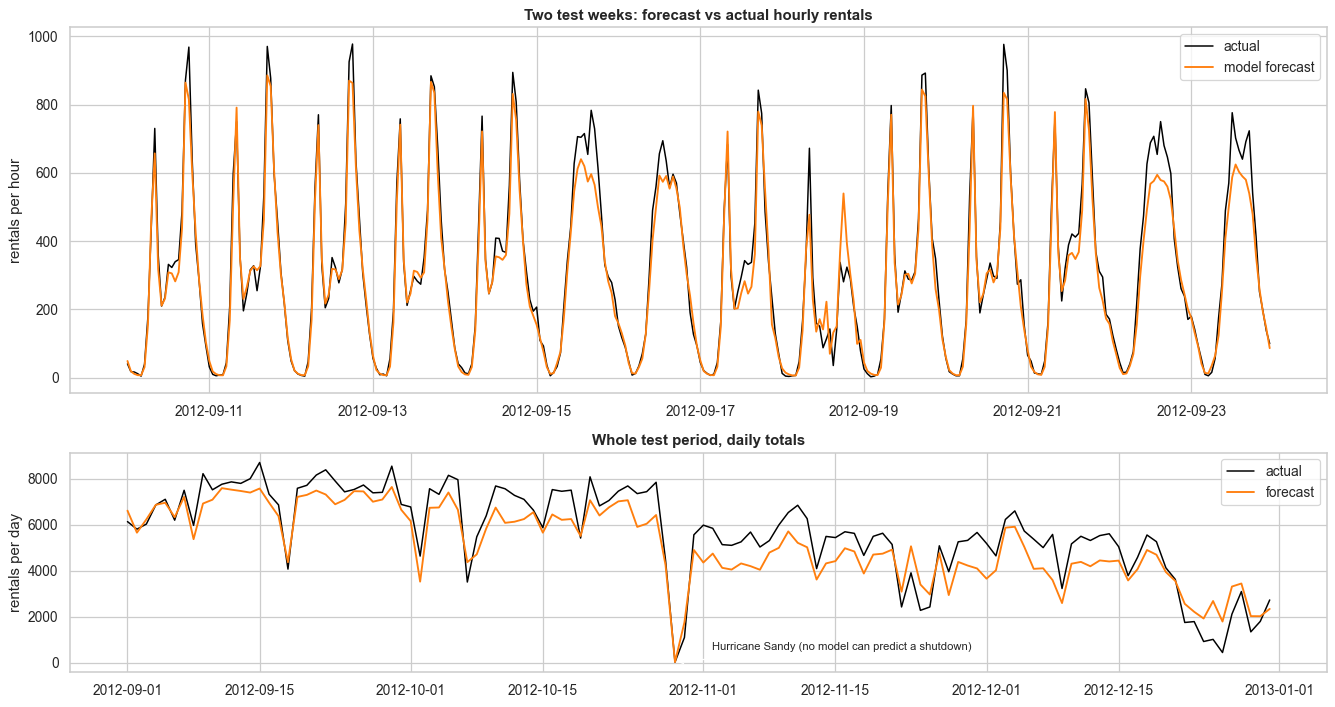

In [5]:
window = (hour.dteday >= "2012-09-10") & (hour.dteday < "2012-09-24")
fig, axes = plt.subplots(2, 1, figsize=(15, 8), gridspec_kw={"height_ratios": [2, 1.2]})
ax = axes[0]
ts = hour.loc[window, "dteday"] + pd.to_timedelta(hour.loc[window, "hr"], unit="h")
ax.plot(ts, hour.loc[window, "cnt"], color="black", lw=1.2, label="actual")
ax.plot(ts, pred.loc[ts.index, "Two models (members + casual)"], color="tab:orange", lw=1.5, label="model forecast")
ax.set(title="Two test weeks: forecast vs actual hourly rentals", ylabel="rentals per hour"); ax.legend()

daily_err = pd.DataFrame({"actual": y, "pred": pred["Two models (members + casual)"],
                          "dteday": hour.loc[test, "dteday"]}).groupby("dteday").sum()
axes[1].plot(daily_err.index, daily_err.actual, color="black", lw=1.2, label="actual")
axes[1].plot(daily_err.index, daily_err.pred, color="tab:orange", lw=1.5, label="forecast")
sandy = pd.Timestamp("2012-10-29")
axes[1].annotate("Hurricane Sandy (no model can predict a shutdown)", (sandy, daily_err.loc[sandy, "actual"]),
                 xytext=(30, 10), textcoords="offset points", arrowprops=dict(arrowstyle="->"), fontsize=9)
axes[1].set(title="Whole test period, daily totals", ylabel="rentals per day"); axes[1].legend()
plt.tight_layout(); plt.show()

### What drives demand? (permutation importance on the test period)
How much the error grows when each feature is randomly shuffled. A bigger drop means the model relies on that feature more.

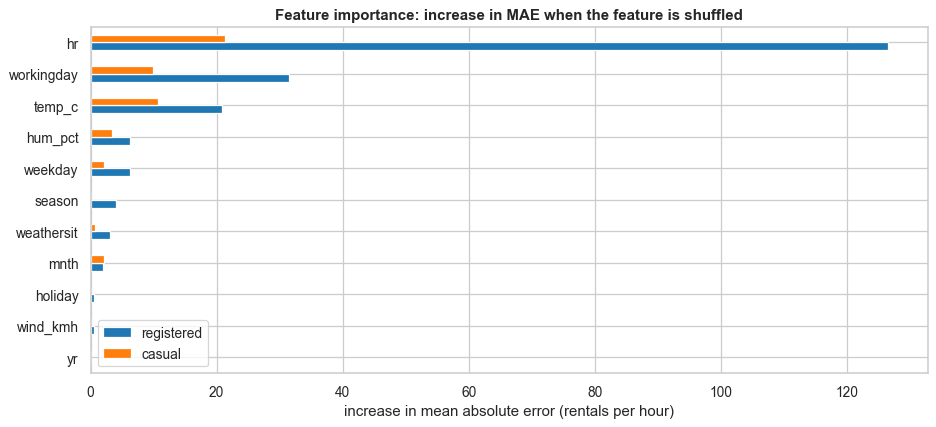

In [6]:
imp = {}
for t in ["registered", "casual"]:
    r = permutation_importance(models[t], X[test], targets[t][test], n_repeats=5, random_state=0,
                               scoring="neg_mean_absolute_error")
    imp[t] = pd.Series(r.importances_mean, index=X.columns)
imp = pd.DataFrame(imp).sort_values("registered")

imp.plot.barh(figsize=(12, 5), color=["tab:blue", "tab:orange"])
plt.title("Feature importance: increase in MAE when the feature is shuffled")
plt.xlabel("increase in mean absolute error (rentals per hour)"); plt.ylabel("")
plt.show()

**Reading these results:**
- **Hour of day** dominates for members (commute timing), followed by working day and temperature. Casual riders depend more evenly on hour, temperature and working day (leisure riding needs nice weather and free time).
- `yr` shows zero importance here only because every test hour is in 2012, so shuffling it changes nothing. It still matters for the level of demand.
- The forecast runs about 10–15 % **low in Nov–Dec 2012**. Demand kept growing beyond anything in the training data, and tree models can't extrapolate a trend. This is the main weakness, and it's why the planning number below is calibrated, and why growth is applied as an explicit multiplier.

## 5. From rentals to bikes in use

A bike rented for 12 minutes is busy for 12/60 = 0.2 of an hour. By Little's law, the average number of bikes out on trips during an hour is:

$$\text{bikes in use} = \text{member rentals} \times \tfrac{12}{60} + \text{casual rentals} \times \tfrac{30}{60}$$

We then fit a **quantile model** (90th percentile) directly on bikes in use. Instead of the *average* demand, it predicts the level that demand stays under **9 hours out of 10**: a planning number with a safety margin built in.

**Calibration.** A quantile model trained on the past under-covers when demand keeps growing, and 2012 kept growing. So we use **split-conformal calibration**:
- fit on Jan 2011 – Jun 2012
- on Jul – Aug 2012 (not used for fitting), find the factor the plan must be scaled by so that 90 % of busy hours fall under it
- check on Sep – Dec 2012 (still unseen) whether the scaled plan really covers about 90 %

In [7]:
hour["in_use"] = bm.bikes_in_use(hour.registered, hour.casual)
fit_q = hour.dteday < "2012-07-01"
calib = train & ~fit_q

def q90_model():
    return HistGradientBoostingRegressor(loss="quantile", quantile=0.9, max_iter=600, learning_rate=0.05,
                                         random_state=0, **best)

q90 = q90_model().fit(X[fit_q], hour.in_use[fit_q])
raw_plan = pd.Series(q90.predict(X), index=hour.index)
busy = calib & (hour.in_use > 5)  # ignore near-empty night hours, where ratios are meaningless
factor = np.quantile(hour.in_use[busy] / raw_plan[busy].clip(lower=1), 0.9)

hour.loc[test, "in_use_q90"] = raw_plan[test] * factor
hour.loc[test, "in_use_mean"] = bm.bikes_in_use(models["registered"].predict(X[test]), models["casual"].predict(X[test]))

t = hour[test]
cover = lambda plan, m=slice(None): (t.in_use[m] <= plan[m]).mean()
print(f"calibration factor: x{factor:.3f}")
print(f"test coverage before calibration: {cover(raw_plan[test]):.1%} overall, {cover(raw_plan[test], peak_mask):.1%} at working-day peaks")
print(f"test coverage after calibration : {cover(t.in_use_q90):.1%} overall, {cover(t.in_use_q90, peak_mask):.1%} at working-day peaks  (target 90%)")

calibration factor: x1.126
test coverage before calibration: 76.2% overall, 54.8% at working-day peaks
test coverage after calibration : 91.0% overall, 89.2% at working-day peaks  (target 90%)


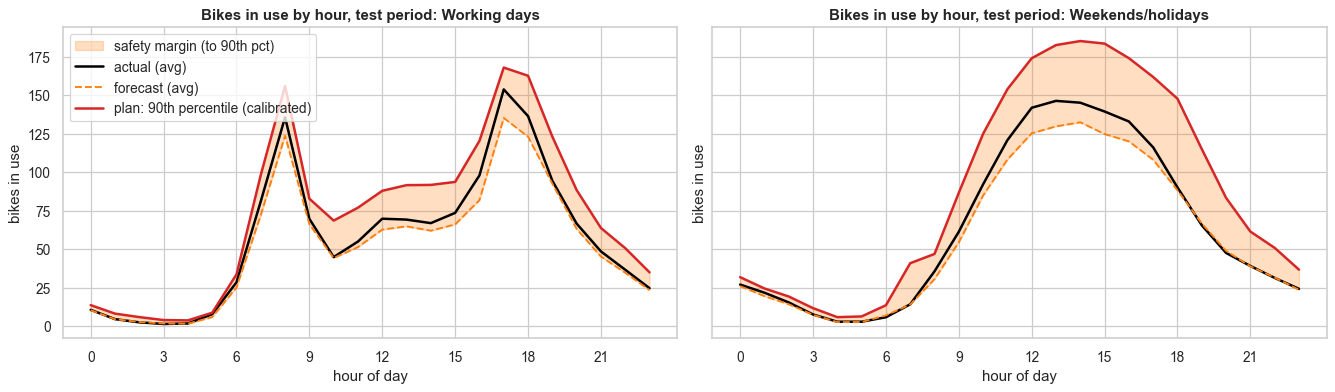

In [8]:
prof = t.groupby(["workingday", "hr"])[["in_use", "in_use_mean", "in_use_q90"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, (wd, label) in zip(axes, [(1, "Working days"), (0, "Weekends/holidays")]):
    p = prof.loc[wd]
    ax.fill_between(p.index, p.in_use_mean, p.in_use_q90, color="tab:orange", alpha=0.25, label="safety margin (to 90th pct)")
    ax.plot(p.index, p.in_use, color="black", lw=2, label="actual (avg)")
    ax.plot(p.index, p.in_use_mean, color="tab:orange", ls="--", label="forecast (avg)")
    ax.plot(p.index, p.in_use_q90, color="tab:red", lw=2, label="plan: 90th percentile (calibrated)")
    ax.set(title=f"Bikes in use by hour, test period: {label}", xlabel="hour of day", ylabel="bikes in use", xticks=range(0, 24, 3))
axes[0].legend()
plt.tight_layout(); plt.show()

**Important difference from rentals.** In *rentals*, the working-day commute is the clear peak (Part 2). In *bikes in use*, weekend afternoons are just as high. Casual riders keep a bike about 2.5× longer, so a leisure afternoon ties up bikes for many hours in a row. So the fleet is tested in **two windows**: working-day evenings (17:00–18:00) and weekend afternoons (11:00–17:00). This depends on the casual trip length assumption, which is why it's in the sensitivity table.

## 6. How many bikes? Sizing the fleet

Retrain everything on **all two years** (the test is done, so use all the data), then:
1. For every day, take the **busiest hour's 90th-percentile bikes in use**: the most bikes that day needs on the road at once.
2. The fleet must cover nearly all days, so plan for the **95th percentile of those daily peaks**. The handful of busier days are handled operationally.
3. Add parked bikes (availability buffer) and repairs to get the **total fleet**.

In [9]:
final = {t: hgb(**best).fit(X, targets[t]) for t in ["registered", "casual"]}
final_q90 = q90_model().fit(X, hour.in_use)
hour["plan_in_use"] = final_q90.predict(X) * factor  # same calibration factor as validated above

days = hour.groupby("dteday").agg(peak_plan=("plan_in_use", "max"), avg_in_use=("in_use", "mean"),
                                  peak_actual=("in_use", "max"), workingday=("workingday", "first"), yr=("yr", "first"))
d12 = days[days.yr == 1]  # size for the latest year's demand level
design_in_use = d12.peak_plan.quantile(0.95)
fleet = bm.fleet_needed(design_in_use)

print(f"Design peak (95th pct of 2012 daily peaks): {design_in_use:,.0f} bikes on the road at once")
print(f"+ {bm.AVAILABILITY_BUFFER:.1f} parked per bike in use, + {bm.MAINTENANCE_SHARE:.0%} in repair")
print(f"=> total fleet needed: about {fleet:,.0f} bikes")
print()
print(f"Average bikes in use across all 2012 hours: {hour.loc[hour.yr == 1, 'in_use'].mean():,.0f}")
print(f"=> an average bike is on a trip only {hour.loc[hour.yr == 1, 'in_use'].mean() / fleet:.0%} of the time")

Design peak (95th pct of 2012 daily peaks): 259 bikes on the road at once
+ 1.5 parked per bike in use, + 10% in repair
=> total fleet needed: about 719 bikes

Average bikes in use across all 2012 hours: 60
=> an average bike is on a trip only 8% of the time


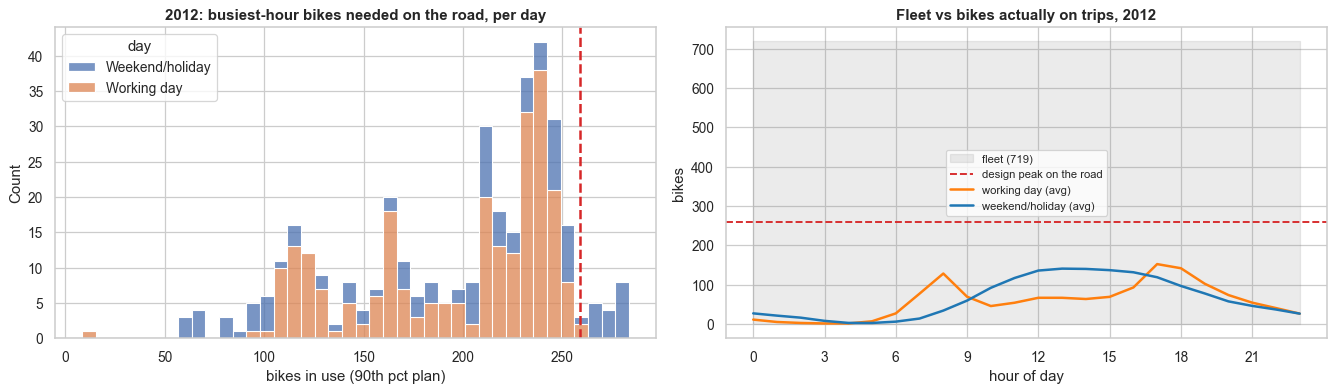

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(data=d12.assign(day=d12.workingday.map({1: "Working day", 0: "Weekend/holiday"})),
             x="peak_plan", hue="day", bins=40, ax=axes[0], multiple="stack")
axes[0].axvline(design_in_use, color="tab:red", lw=2, ls="--", label=f"design peak = {design_in_use:,.0f}")
axes[0].set(title="2012: busiest-hour bikes needed on the road, per day", xlabel="bikes in use (90th pct plan)")

h12 = hour[hour.yr == 1]
avg_day = h12.groupby(["workingday", "hr"]).in_use.mean().unstack(0)
axes[1].fill_between(range(24), 0, fleet, color="tab:gray", alpha=0.15, label=f"fleet ({fleet:,.0f})")
axes[1].axhline(design_in_use, color="tab:red", ls="--", label="design peak on the road")
axes[1].plot(avg_day.index, avg_day[1], color="tab:orange", lw=2, label="working day (avg)")
axes[1].plot(avg_day.index, avg_day[0], color="tab:blue", lw=2, label="weekend/holiday (avg)")
axes[1].set(title="Fleet vs bikes actually on trips, 2012", xlabel="hour of day", ylabel="bikes", xticks=range(0, 24, 3))
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

### Where and when the fleet binds
Share of hours in 2012 where the 90th-percentile plan exceeds **80 % of the design peak**. These are the only hours where the fleet size is actually tested.

Only 7.0% of all 2012 hours are near capacity. Of those:
  working-day 17:00-18:00     : 43%
  weekend/holiday 11:00-17:00 : 52%


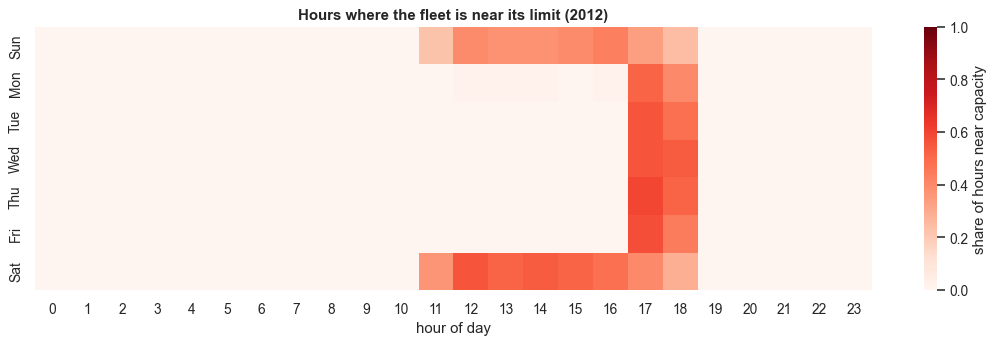

In [11]:
h12 = hour[hour.yr == 1].copy()
h12["tight"] = h12.plan_in_use > 0.8 * design_in_use
pivot = h12.pivot_table(index="weekday", columns="hr", values="tight", aggfunc="mean")
pivot.index = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
plt.figure(figsize=(15, 3.8))
sns.heatmap(pivot, cmap="Reds", vmin=0, vmax=1, cbar_kws={"label": "share of hours near capacity"})
plt.title("Hours where the fleet is near its limit (2012)"); plt.xlabel("hour of day"); plt.ylabel("")
plt.show()
tight = h12[h12.tight]
evening = tight.workingday.eq(1) & tight.hr.isin([17, 18])
weekend_aft = tight.workingday.eq(0) & tight.hr.between(11, 17)
print(f"Only {h12.tight.mean():.1%} of all 2012 hours are near capacity. Of those:")
print(f"  working-day 17:00-18:00     : {evening.mean():.0%}")
print(f"  weekend/holiday 11:00-17:00 : {weekend_aft.mean():.0%}")

## 7. Sensitivity: how much do the assumptions matter?

The fleet number depends on assumptions that aren't in the data. The table refits the 90th-percentile model for each pair of trip lengths and recomputes the total fleet for different availability buffers (10 % in repair throughout).

In [12]:
rows = []
for reg_min, cas_min in [(10, 25), (12, 30), (15, 35), (20, 40)]:
    in_use = (hour.registered * reg_min + hour.casual * cas_min) / 60
    m = q90_model().fit(X, in_use)
    daily_peak = pd.Series(m.predict(X) * factor).groupby(hour.dteday.values).max()
    peak = daily_peak[daily_peak.index.year == 2012].quantile(0.95)
    for buffer in [1.0, 1.5, 2.0, 2.5]:
        rows.append({"trip length (member / casual)": f"{reg_min} / {cas_min} min", "buffer": buffer,
                     "fleet": bm.fleet_needed(peak, buffer=buffer)})
sens = pd.DataFrame(rows).pivot(index="trip length (member / casual)", columns="buffer", values="fleet")
sens.columns = [f"buffer {b}" for b in sens.columns]
sens.round(-1).astype(int)

,buffer 1.0,buffer 1.5,buffer 2.0,buffer 2.5
trip length (member / casual),,,,
10 / 25 min,480,600,720,840
12 / 30 min,580,720,860,1010
15 / 35 min,700,870,1050,1220
20 / 40 min,880,1100,1330,1550


## 8. The trade-off: how many busy days should the fleet cover?

Every extra bike buys coverage for fewer and fewer days. The table shows the fleet needed if it is sized to cover different shares of 2012 days, and how many days a year would go over capacity. Those days are what peak management (rebalancing, pricing, trip time limits) has to absorb instead of new bikes.

In [13]:
rows = []
for pct in [0.75, 0.80, 0.90, 0.95, 0.99, 1.00]:
    peak = d12.peak_plan.quantile(pct)
    over = d12[d12.peak_plan > peak]
    rows.append({"days covered": f"{pct:.0%}", "design peak (on road)": peak, "total fleet": bm.fleet_needed(peak),
                 "days over capacity / yr": len(over),
                 "of which weekends/holidays": int((over.workingday == 0).sum())})
trade = pd.DataFrame(rows).set_index("days covered")
trade["extra bikes vs 80%"] = trade["total fleet"] - trade.loc["80%", "total fleet"]
trade.round(0).astype(int)

,design peak (on road),total fleet,days over capacity / yr,of which weekends/holidays,extra bikes vs 80%
days covered,,,,,
75%,238,661,92,39,-9
80%,241,670,73,37,0
90%,249,691,37,26,21
95%,259,719,19,18,49
99%,279,776,4,4,106
100%,283,787,0,0,117


In [14]:
growth = 1.20  # e.g. next year's demand 20 % higher (2011 -> 2012 was +65 %)
fleet80 = trade.loc["80%", "total fleet"]
print(f"Fleet covering 95% of days (recommended plan) : {fleet:,.0f} bikes")
print(f"Fleet covering 80% of days + peak management   : {fleet80:,.0f} bikes ({fleet - fleet80:,.0f} fewer)")
print(f"Same two plans with +20% demand growth         : {fleet * growth:,.0f} / {fleet80 * growth:,.0f} bikes")

Fleet covering 95% of days (recommended plan) : 719 bikes
Fleet covering 80% of days + peak management   : 670 bikes (49 fewer)
Same two plans with +20% demand growth         : 863 / 804 bikes


## 9. Save the model for the prototype
The final models (trained on all data) and the design numbers are saved so the Part 4 prototype can answer questions from them.

In [15]:
Path("Model").mkdir(exist_ok=True)
joblib.dump({"registered": final["registered"], "casual": final["casual"], "in_use_q90": final_q90,
             "calibration_factor": factor, "design_in_use": design_in_use, "fleet": fleet,
             "test_metrics": results, "tradeoff": trade},
            "Model/bike_demand.joblib")
print("saved Model/bike_demand.joblib")

# Quick check that a what-if scenario works end to end
s = bm.scenario_hours("2013-06-14", weathersit=3, temp_c=24)  # a rainy Friday in June
sx = bm.make_features(s)
plan = final_q90.predict(sx) * factor
print(f"Rainy Friday 14 Jun: peak plan {plan.max():,.0f} bikes on the road at {int(plan.argmax()):02d}:00")

saved Model/bike_demand.joblib
Rainy Friday 14 Jun: peak plan 217 bikes on the road at 17:00


## 10. Answer to the CEO

**Should we just buy more bikes? Not before checking two things.**

**What the model says**

| | Result |
|---|---|
| Forecast accuracy (4 unseen months) | R² **0.91** vs 0.68 for the baseline; error at working-day peaks **84** vs 131 rentals/hour |
| Planning margin | 90th-percentile plan, calibrated: covers **91 %** of unseen hours (89 % at working-day peaks) |
| Design peak (2012, 95 % of days) | about **260 bikes on the road at once** |
| **Fleet needed** | **about 720 bikes** (plausible range **600–1,100** depending on trip length and buffer) |
| Average utilisation | a bike is on a trip only **~8 %** of the time |
| When the fleet is tested | only **7 %** of hours: working-day 17:00–18:00 and weekend afternoons 11:00–17:00 |
| Cost of covering more days | 80 % → 95 % of days costs only **~50 more bikes**; at 95 %, 18 of the 19 days over capacity are weekends |

**What it means**
1. **Both complaints are true at once.** The fleet is sized by a few hours a week; the rest of the time ~90 % of bikes are parked. Buying bikes adds capacity for all 168 hours a week to solve a problem in about 12 of them.
2. **The two pressure windows need different fixes.** Working-day evenings are a *distribution* problem (bikes need to be where commuters start, so rebalance before 16:00). Weekend afternoons are a *trip-length* problem (leisure riders keep bikes long, so use trip time limits or pricing, and supply near parks and tourist areas).

**Recommendation**
1. **Compare the real fleet with ~720 (range 600–1,100).**
   - If the company already runs more bikes than this, the shortages **can't be a city-wide fleet-size problem**. They're about *where* the bikes are, so rebalance, don't buy.
   - If it runs fewer, buy only the gap, sized with this model and a growth assumption (+20 % growth → ~860 bikes).
2. **Run the rebalancing pilot from Part 2** (pre-peak rebalancing vs +10 % bikes, measured by empty-station minutes at peak) before any large purchase.
3. **Collect station-level data** (dock status every few minutes, trip origins, destinations and durations). It replaces the two biggest assumptions here with measurements and shows *where* bikes run out.

**Limitations**
- Trip lengths and the availability buffer are assumptions. The sensitivity table shows the fleet moves from ~600 to ~1,100 with them, so they should be measured.
- Recorded rentals understate true peak demand (failed rentals aren't logged), so the design peak is a **floor**.
- The model has only seen 2011–2012. Demand was still growing, which is why the plan needed calibrating; future growth is applied as a separate multiplier, not learned.
- City-wide data can't see spatial imbalance, the likeliest cause of "can't find a bike".